# 04. Ансамбль, перенос между датасетами, устойчивость, выбор финальной модели

**Цель этапа:** проверить, улучшает ли ансамбль моделей качество; выяснить, переносятся ли модели на данные
другого происхождения (RadioML ↔ свой генератор) и насколько они устойчивы к искажениям реального эфира;
обоснованно выбрать финальную модель для продукта.

**Шаги:**
1. Ансамбль: усреднение вероятностей и stacking (метамодель на val) — бустинг на признаках + нейросети.
2. Перенос между датасетами (cross-dataset).
3. Устойчивость: сдвиг частоты, инверсия спектра; по параметрам канала своего датасета.
4. Скорость инференса и выбор финальной модели.
5. Выводы.

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.linear_model import LogisticRegression
from statsmodels.stats.contingency_tables import mcnemar

from amc.data import load_rml2016a, load_synth
from amc.generator import CLASSES
from amc.models import n_params
from amc.predict import DEEP, load_model, perturb, predict_proba

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures" / "analysis"
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")


def savefig(name: str) -> None:
    """Сохранить рисунок."""
    plt.savefig(FIG / f"{name}.png", dpi=120, bbox_inches="tight")


def proba(run: str) -> np.ndarray:
    """Сохранённые вероятности запуска (порядок примеров = порядок датасета)."""
    return np.load(DEEP / run / "proba.npz", allow_pickle=True)["proba"]


def lgbm(name: str) -> np.ndarray:
    """Вероятности LightGBM на признаках."""
    return np.load(ROOT / "models" / "baseline" / f"{name}_lgbm.npz", allow_pickle=True)["proba"]


def pick(prefix: str, seed: int = 0) -> str:
    """Лучший по **val** запуск конфигурации (варианты 25/60 эпох); тест для выбора не используется."""
    c = list(DEEP.glob(f"{prefix}_s{seed}*/metrics.json"))
    return max(c, key=lambda f: json.loads(f.read_text(encoding="utf-8"))["metrics"]["val_acc"]).parent.name


def mcn(a: np.ndarray, b: np.ndarray) -> float:
    """p-значение Мак-Немара для векторов «верно/неверно»."""
    tbl = [[np.sum(a & b), np.sum(a & ~b)], [np.sum(~a & b), np.sum(~a & ~b)]]
    return mcnemar(tbl, exact=False, correction=True).pvalue

## 1. Ансамбль

Члены ансамбля: LightGBM на экспертных признаках, ResNet-1D, CNN-LSTM (seed 0).
- **Усреднение вероятностей** — без обучения.
- **Stacking**: метамодель (логистическая регрессия) обучается на вероятностях членов ансамбля **на val**
  (базовые модели val не видели) и проверяется на тесте. Признаки метамодели — логарифмы вероятностей
  всех членов (33 признака).

In [2]:
ens_rows = {}
for data, Xmeta in [("rml2016a", load_rml2016a()[1]), ("synth_v1", load_synth()[1])]:
    members = {"LightGBM": lgbm(data), "ResNet": proba(pick(f"{data}_resnet_iq_aug")),
               "CNN-LSTM": proba(pick(f"{data}_cnnlstm_iq_aug"))}
    y = Xmeta["label"].to_numpy()
    split = Xmeta["split"].to_numpy()
    snr = Xmeta["snr_db"].to_numpy()
    va, te = split == "val", split == "test"
    res = {k: v.argmax(1) for k, v in members.items()}
    res["среднее (нейросети)"] = (members["ResNet"] + members["CNN-LSTM"]).argmax(1)
    res["среднее (все)"] = sum(members.values()).argmax(1)
    F = np.log(np.concatenate(list(members.values()), axis=1) + 1e-7)
    meta_lr = LogisticRegression(max_iter=3000, C=1.0).fit(F[va], y[va])
    res["stacking"] = meta_lr.predict(F)
    best_single = max(["ResNet", "CNN-LSTM"], key=lambda k: (res[k][va] == y[va]).mean())
    rows = []
    for k, p in res.items():
        c = p[te] == y[te]
        rows.append({"модель": k, "acc": c.mean(), "acc ОСШ≥0": c[snr[te] >= 0].mean(),
                     "acc ОСШ≥10": c[snr[te] >= 10].mean(),
                     f"p Мак-Немар vs {best_single}": mcn(c, res[best_single][te] == y[te]) if k != best_single else np.nan})
    ens_rows[data] = pd.DataFrame(rows).set_index("модель")
    print(data)
    display(ens_rows[data].round(4))  # noqa: F821

rml2016a


,acc,acc ОСШ≥0,acc ОСШ≥10,p Мак-Немар vs CNN-LSTM
модель,,,,
LightGBM,0.5477,0.8372,0.8586,0.0000
ResNet,0.6159,0.9145,0.9230,0.0003
CNN-LSTM,0.6201,0.9150,0.9232,NaN
среднее (нейросети),0.6231,0.9208,0.9265,0.0004
среднее (все),0.6246,0.9225,0.9283,0.0000
stacking,0.6275,0.9217,0.9263,0.0000


synth_v1


,acc,acc ОСШ≥0,acc ОСШ≥10,p Мак-Немар vs CNN-LSTM
модель,,,,
LightGBM,0.5145,0.7526,0.8227,0.0
ResNet,0.5958,0.8694,0.9053,0.0
CNN-LSTM,0.6290,0.8863,0.9147,NaN
среднее (нейросети),0.6349,0.8964,0.9262,0.0
среднее (все),0.6433,0.9009,0.9315,0.0
stacking,0.6506,0.9080,0.9371,0.0


## 2. Перенос между датасетами
Модель, обученная на одном датасете, проверяется на тесте другого (окна 128 отсчётов; классы совпадают).
Это проверка на «новых данных» другого происхождения (критерий воспроизводимости).

In [3]:
Xr, Mr, _ = load_rml2016a()
Xs, Ms, _ = load_synth()
te_r = np.flatnonzero(Mr["split"].to_numpy() == "test")
te_s = np.flatnonzero(Ms["split"].to_numpy() == "test")
Xs128 = np.asarray(Xs[np.sort(te_s), :, :128])
ys128 = Ms["label"].to_numpy()[np.sort(te_s)]
ss128 = Ms["snr_db"].to_numpy()[np.sort(te_s)]
cross = []
for run, train_on in [(pick("rml2016a_resnet_iq_aug"), "RadioML"), (pick("rml2016a_cnnlstm_iq_aug"), "RadioML"),
                      (pick("synth_v1_128_resnet_iq_aug"), "свой (128)")]:
    model, cfg = load_model(run)
    for test_on, Xt, yt, st in [("RadioML", Xr[te_r], Mr["label"].to_numpy()[te_r], Mr["snr_db"].to_numpy()[te_r]),
                                ("свой (128)", Xs128, ys128, ss128)]:
        p = predict_proba(model, cfg, Xt).argmax(1)
        c = p == yt
        cross.append({"модель": run, "обучена на": train_on, "тест на": test_on, "acc": c.mean(),
                      "acc ОСШ≥10": c[st >= 10].mean()})
    del model
    torch.cuda.empty_cache()
pd.DataFrame(cross).round(4)

,модель,обучена на,тест на,acc,acc ОСШ≥10
0,rml2016a_resnet_iq_aug_s0,RadioML,RadioML,0.6159,0.9230
1,rml2016a_resnet_iq_aug_s0,RadioML,свой (128),0.1304,0.1543
2,rml2016a_cnnlstm_iq_aug_s0,RadioML,RadioML,0.6201,0.9232
3,rml2016a_cnnlstm_iq_aug_s0,RadioML,свой (128),0.1331,0.1542
4,synth_v1_128_resnet_iq_aug_s0,свой (128),RadioML,0.4516,0.7307
5,synth_v1_128_resnet_iq_aug_s0,свой (128),свой (128),0.4250,0.7210


## 3. Устойчивость к искажениям
### 3.1. Сдвиг частоты и инверсия спектра (RadioML, тест, ОСШ ≥ 0 дБ)
Модели с аугментациями и без — на одних и тех же искажённых данных.

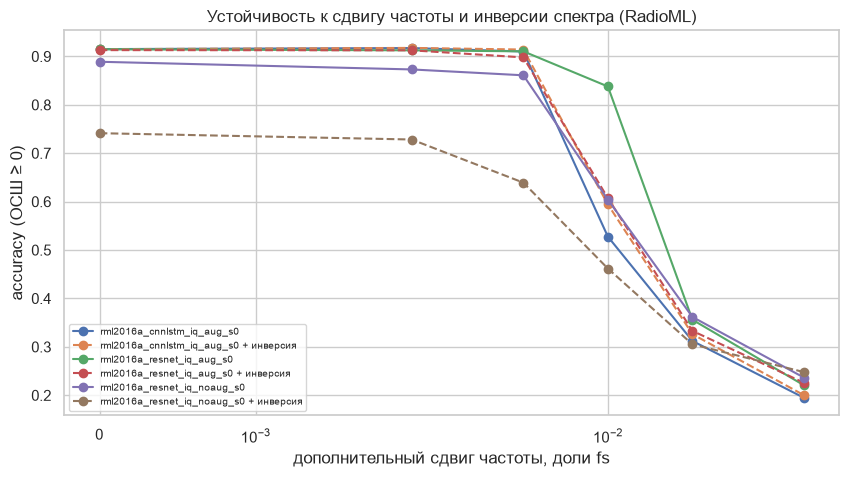

сдвиг частоты, доли fs                0.000  0.002  0.005  0.010  0.020  0.050
модель                      инверсия                                          
rml2016a_cnnlstm_iq_aug_s0  False     0.915  0.917  0.910  0.528  0.312  0.195
                            True      0.915  0.918  0.914  0.594  0.326  0.200
rml2016a_resnet_iq_aug_s0   False     0.915  0.912  0.910  0.838  0.356  0.220
                            True      0.913  0.912  0.898  0.607  0.333  0.226
rml2016a_resnet_iq_noaug_s0 False     0.889  0.873  0.861  0.604  0.362  0.236
                            True      0.741  0.728  0.639  0.462  0.305  0.248

In [4]:
m0 = te_r[Mr["snr_db"].to_numpy()[te_r] >= 0]
Xt, yt = Xr[m0], Mr["label"].to_numpy()[m0]
robust = []
for run in ["rml2016a_resnet_iq_aug_s0", "rml2016a_resnet_iq_noaug_s0", pick("rml2016a_cnnlstm_iq_aug")]:
    model, cfg = load_model(run)
    for cfo in [0, 0.002, 0.005, 0.01, 0.02, 0.05]:
        for conj in [False, True]:
            acc = (predict_proba(model, cfg, perturb(Xt, cfo=cfo, conj=conj)).argmax(1) == yt).mean()
            robust.append({"модель": run, "сдвиг частоты, доли fs": cfo, "инверсия": conj, "acc": acc})
    del model
    torch.cuda.empty_cache()
rb = pd.DataFrame(robust)
fig, ax = plt.subplots(figsize=(10, 5))
for (run, conj), g in rb.groupby(["модель", "инверсия"]):
    ax.plot(g["сдвиг частоты, доли fs"], g["acc"], marker="o", ls="--" if conj else "-",
            label=f"{run}{' + инверсия' if conj else ''}")
ax.set_xscale("symlog", linthresh=0.002)
ax.set_xlabel("дополнительный сдвиг частоты, доли fs")
ax.set_ylabel("accuracy (ОСШ ≥ 0)")
ax.legend(fontsize=7)
ax.set_title("Устойчивость к сдвигу частоты и инверсии спектра (RadioML)")
savefig("robust_cfo")
plt.show()
rb.pivot_table(index=["модель", "инверсия"], columns="сдвиг частоты, доли fs", values="acc").round(3)

### 3.2. Точность в зависимости от условий канала (свой датасет, лучшая модель, ОСШ ≥ 0 дБ)
Метаданные генератора позволяют разложить ошибки по параметрам канала.

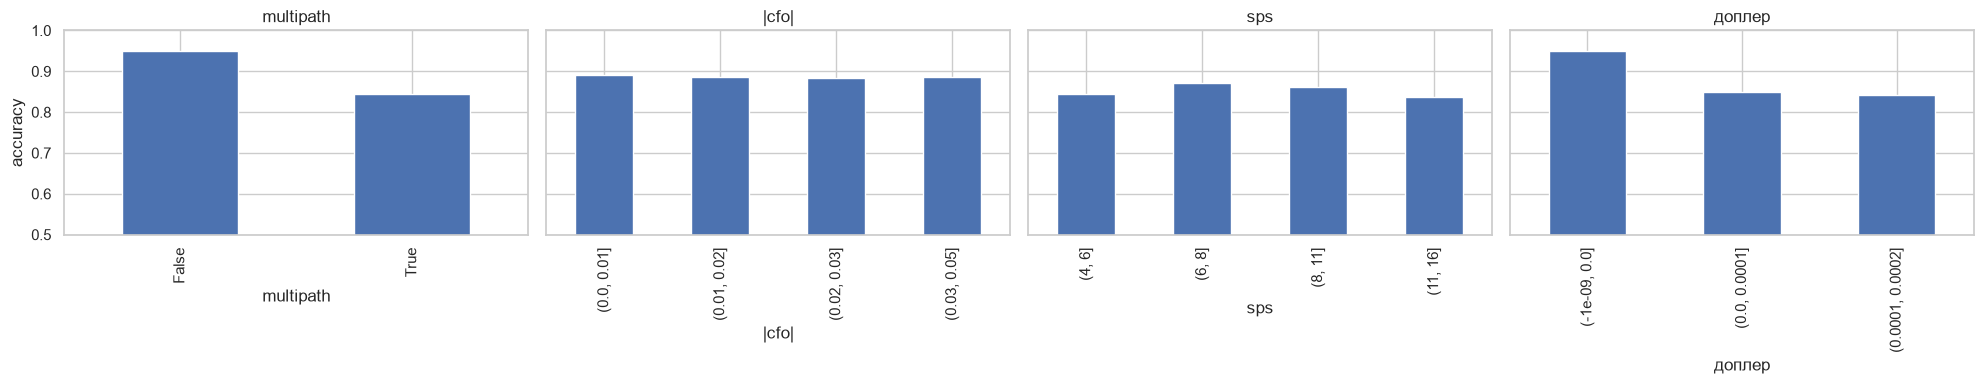

In [5]:
best_s = pick("synth_v1_cnnlstm_iq_aug")
ps = proba(best_s).argmax(1)
d = Ms.iloc[te_s].copy()
d = d[d.snr_db >= 0]
d["верно"] = ps[d.index] == d["label"].to_numpy()
d["|cfo|"] = pd.cut(d["cfo"].abs(), [0, 0.01, 0.02, 0.03, 0.05])
d["sps"] = pd.cut(d["sps"], [4, 6, 8, 11, 16])
d["доплер"] = pd.cut(d["doppler"], [-1e-9, 0, 1e-4, 2e-4])
fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharey=True)
for ax, col in zip(axes, ["multipath", "|cfo|", "sps", "доплер"]):
    d.groupby(col, observed=True)["верно"].mean().plot.bar(ax=ax)
    ax.set_title(col)
    ax.set_ylim(0.5, 1)
axes[0].set_ylabel("accuracy")
plt.tight_layout()
savefig("acc_by_channel")
plt.show()

## 4. Скорость инференса и выбор финальной модели

In [6]:
speed = []
dev = "cuda" if torch.cuda.is_available() else "cpu"
for run in [pick("rml2016a_resnet_iq_aug"), pick("rml2016a_cnnlstm_iq_aug"), pick("rml2016a_vtcnn2_iq_aug"),
            pick("synth_v1_resnet_iq_aug"), pick("synth_v1_cnnlstm_iq_aug")]:
    for device in sorted({dev, "cpu"}):
        model, cfg = load_model(run, device)
        n = cfg["_length"]
        Xb = np.random.default_rng(0).standard_normal((2048, 2, n)).astype(np.float32)
        predict_proba(model, cfg, Xb[:256])
        t0 = time.perf_counter()
        predict_proba(model, cfg, Xb)
        dt = time.perf_counter() - t0
        speed.append({"модель": run, "устройство": device, "параметров": n_params(model),
                      "окон/с": len(Xb) / dt, "мс на окно": 1000 * dt / len(Xb)})
        del model
pd.DataFrame(speed).round(3)

,модель,устройство,параметров,окон/с,мс на окно
0,rml2016a_resnet_iq_aug_s0,cpu,1284747,3299.174,0.303
1,rml2016a_resnet_iq_aug_s0,cuda,1284747,73499.065,0.014
2,rml2016a_cnnlstm_iq_aug_s0,cpu,276683,15570.344,0.064
3,rml2016a_cnnlstm_iq_aug_s0,cuda,276683,110941.977,0.009
4,rml2016a_vtcnn2_iq_aug_s0,cpu,2830427,4345.312,0.230
5,rml2016a_vtcnn2_iq_aug_s0,cuda,2830427,73595.205,0.014
6,synth_v1_resnet_iq_aug_s0,cpu,1284747,411.386,2.431
7,synth_v1_resnet_iq_aug_s0,cuda,1284747,9468.668,0.106
8,synth_v1_cnnlstm_iq_aug_s0_e60,cpu,276683,1722.765,0.580
9,synth_v1_cnnlstm_iq_aug_s0_e60,cuda,276683,30798.521,0.032


## 5. Выводы

1. **Ансамбль значимо лучше лучшей одиночной модели.** Stacking (логистическая регрессия на логарифмах
   вероятностей, обучена на val): свой датасет 65,1 % (ОСШ ≥ 0: 90,8 %, ≥ 10: 93,7 %) против CNN-LSTM 62,9 %
   (+2,2 п.п.); RadioML 62,75 % против 62,0 % (+0,7 п.п.); Мак-Немар p < 1e-3 на обоих. Простое усреднение
   всех трёх моделей почти так же хорошо (64,3 % / 62,5 %) и не требует обучения. Бустинг на признаках, будучи
   слабее по отдельности, полезен в ансамбле: «среднее (все)» > «среднее (нейросети)» — признаки несут
   дополнительную информацию.
2. **Перенос между датасетами.** Модели RadioML на данных своего генератора — 13 % (уровень угадывания 9 %):
   они выучили особенности RadioML (узкий сдвиг частоты, дефекты AM/WBFM), а не модуляции. Модель своего
   генератора на RadioML — 45 % (73 % при ОСШ ≥ 10 дБ), т.е. переносится заметно лучше, чем наоборот, хотя
   генераторы разные. Это главный аргумент за собственный генератор с реалистичным каналом.
3. **Устойчивость.** Модели RadioML с аугментациями устойчивы к сдвигу до 0,005 fs (обучающий диапазон),
   при 0,01 fs CNN-LSTM падает до 53 %, ResNet держится (84 %), при ≥ 0,02 fs обе ломаются (≈ 30 %).
   Без аугментаций инверсия спектра стоит 15 п.п. (88,9 → 74,1 %), с аугментациями — 0. Вывод для продукта:
   обучать на широком диапазоне сдвигов (свой генератор: ±0,05 fs) и/или переносить сигнал в ноль перед сетью
   (так и сделано в `infer.py`).
4. **Канал (свой датасет, ОСШ ≥ 0):** многолучёвость — главный фактор ошибок (95 % без неё против 84 % с ней);
   сдвиг частоты в пределах ±0,05 fs на точность не влияет (88–89 % во всех интервалах) — сеть к нему инвариантна;
   отсчётов на символ — слабое влияние (84–87 %). Доплер на рисунке совпадает с многолучёвостью (доплер есть
   только в многолучевом канале), отдельного эффекта не видно.
5. **Скорость инференса:** CNN-LSTM на окнах 1024 — 1 700 окон/с на CPU (0,6 мс), 31 000 окон/с на GPU; ResNet
   на окнах 1024 — в 4 раза медленнее на CPU (2,4 мс/окно). Для продукта этого более чем достаточно: секунда
   записи 48 кГц после передискретизации — десятки окон.
6. **Выбор финальной модели для продукта:** многозадачная сеть ResNet-1D (s2) — она одна даёт и класс, и все
   6 параметров (нужны для перевода в Гц/Бод и для гибрида с ЦОС); её точность классификации (60,5 %, ОСШ ≥ 0:
   87,4 %) ниже stacking (65,1 %), но stacking требует трёх моделей и признаков LightGBM. Компромисс зафиксирован:
   при необходимости максимальной точности классификации ансамбль подключается как отдельный режим (развитие).